# Choosing the Best Tree Depth Using Cross Validation

## About This Project

In this project, you will implement cross validation to pick the best depth (hyperparameter) for a regression tree, again using the ION dataset.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter Notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Get Started

Let's import a few packages that you will need. You will work with the [ION dataset](https://archive.ics.uci.edu/ml/datasets/Ionosphere) for this project.

In [3]:
import numpy as np
from numpy.matlib import repmat
from scipy.io import loadmat
import time

# Non-interactive plots
%matplotlib inline
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


In [4]:
data = loadmat("ion.mat")
xTr = data["xTr"].T
yTr = data["yTr"].flatten()
xTe = data["xTe"].T
yTe = data["yTe"].flatten()
print(f"Number of features: {xTr.shape[1]}")
print(f"Number of training points: {xTr.shape[0]}")
print(f"Number of test points: {xTe.shape[0]}")

Number of features: 34
Number of training points: 281
Number of test points: 70


You are provided a regression-tree-based classifier to use. In addition to what you implemented in the first project, we added a `depth` hyperparameter to the classifier, specified as an argument. This `depth` argument allows us to restrict the maximum depth of the tree model. 

The next code cell shows you how to instantiate a regression tree with no restriction on its depth, train the regression tree, and make predictions. This is equivalent to what you implemented in the previous project.

To create a tree of max depth `k`, you can write:

```Python
tree = RegressionTree(depth=k)
```

In [5]:
# Create a regression tree with no restriction on its depth
tree = RegressionTree(depth=np.inf)

# Fit/train the regression tree
tree.fit(xTr, yTr)

# Use the trained regression tree to make prediction
pred = tree.predict(xTr)

We have also created a function (`mean_squared_loss`) that takes in the prediction (`pred`) and ground truth (`truth`) and returns the average squared loss between the prediction and ground truth.

In [6]:
def mean_squared_loss(pred, truth):
    """
    Calculates the loss between predicted and true labels.

    Input:
        pred: n-dimensional vector of predicted labels
        truth: n-dimensional vector of true labels

    Output:
        loss: average squared loss
    """
    return np.mean((pred - truth) ** 2)

Now, look at the performance of your tree on both the training set and test set using the code cell below.

In [7]:
print(f"Training Loss: {mean_squared_loss(tree.predict(xTr), yTr):.4f}")
print(f"Test Loss: {mean_squared_loss(tree.predict(xTe), yTe):.4f}")

Training Loss: 0.0000
Test Loss: 0.6857


## Implement Cross Validation

As you can see, your tree achives zero training loss on the training set but not zero test loss. Clearly, the tree is overfitting! To reduce overfitting, you need to control the depth of the tree.

One way to pick the optimal depth is to do $k$-fold cross validation. To do so, you will first implement `grid_search`, which finds the best depths given a training set and validation set. Then you will implement `generate_kFold`, which generates a pair of training and validation set for grid search. Finally, you will combine the two functions by implementing `cross_validation`.

### Part One: Implement `grid_search` [Graded]

Implement the function **`grid_search`**, which takes in a training set `xTr, yTr`, a validation set `xVal, yVal` and a list of tree depth candidates `depths`. Your job here is to fit a regression tree for each depth candidate on the training set `xTr, yTr`, evaluate the fitted tree on the validation set `xVal, yVal`, and then pick the candidate that yields the lowest loss for the validation set. 

**Implementation Notes:**

- Use the `mean_squared_loss` function to calculate the training and validation loss for corresponding predictions against true labels `yTr` and `yVal` respectively.

- In the event of a tie, return the depth that appears first in `depths` list (`np.argmin` on the list of validation losses will give you the first index in case of a tie).

In [8]:
def grid_search(xTr, yTr, xVal, yVal, depths):
    """
    Calculates the training and validation loss for trees trained on xTr and validated on yTr with a number of depths.

    Input:
        xTr: nxd training data matrix
        yTr: n-dimensional vector of training labels
        xVal: mxd validation data matrix
        yVal: m-dimensional vector of validation labels
        depths: a list of len k of depths

    Output:
        best_depth, training_losses, validation_losses
        best_depth: the depth that yields that lowest validation loss
        training_losses: a list of len k. the i-th entry corresponds to the the training loss of the tree of depth=depths[i]
        validation_losses: a list of len k. the i-th entry corresponds to the the validation loss of the tree of depth=depths[i]
    """
    training_losses = []
    validation_losses = []
    best_depth = None

    # YOUR CODE HERE
    best_loss = np.inf
    for depth in depths:
        tree = RegressionTree(depth=depth)
        tree.fit(xTr, yTr)
        train_pred = tree.predict(xTr)
        val_pred = tree.predict(xVal)
        train_loss = mean_squared_loss(train_pred, yTr)
        val_loss = mean_squared_loss(val_pred, yVal)
        if val_loss < best_loss:
            best_depth = depth
            best_loss = val_loss

        training_losses.append(train_loss)
        validation_losses.append(val_loss)
        
    # END OF YOUR CODE
    
    return best_depth, training_losses, validation_losses

We can do a dry run with sample depths and plot the training and validation losses against the tree depth. Observe that the training loss continues to decrease with increasing depth, but the validation loss starts to increase after a minimum.

Best Depth: 3
Validation Loss: 0.53


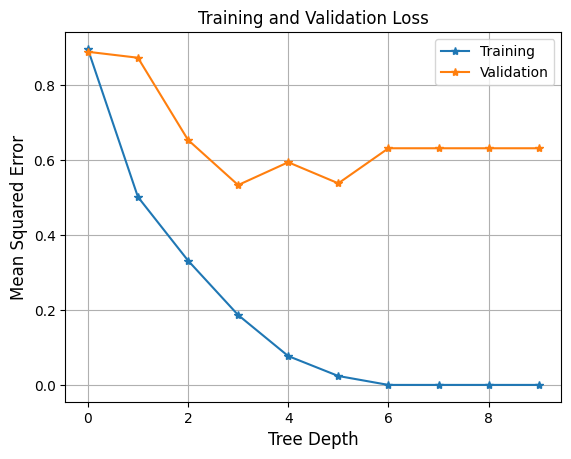

In [9]:
depths = np.arange(10)

# 80-20 split of the training data for demo purposes here
train_split = int(0.8 * xTr.shape[0])
best_depth, training_losses, validation_losses = grid_search(
    xTr[:train_split], yTr[:train_split], xTr[train_split:], yTr[train_split:], depths
)

print(f"Best Depth: {best_depth}")
print(f"Validation Loss: {np.min(validation_losses):.2f}")

plt.figure()
plt.plot(depths, training_losses, "-*", label="Training")
plt.plot(depths, validation_losses, "-*", label="Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Tree Depth", fontsize=12)
plt.ylabel("Mean Squared Error", fontsize=12)
plt.legend()
plt.grid()
plt.show()

Run the next cell to check that your implementation of `grid_search` returns the correct number of training and validation loss values and the correct best depth.

In [10]:
depths = [1, 2, 3, 4, 5]
k = len(depths)

# 80-20 split of the training data
train_split = int(0.8 * xTr.shape[0])
best_depth, training_losses, validation_losses = grid_search(
    xTr[:train_split], yTr[:train_split], xTr[train_split:], yTr[train_split:], depths
)
best_depth_grader, training_losses_grader, validation_losses_grader = (
    grid_search_grader(
        xTr[:train_split],
        yTr[:train_split],
        xTr[train_split:],
        yTr[train_split:],
        depths,
    )
)


def grid_search_test1():
    """
    Check the length of training losses
    """
    return len(training_losses) == k


def grid_search_test2():
    """
    Check the length of validation losses
    """
    return len(validation_losses) == k


def grid_search_test3():
    """
    Check that argmin of validation losses returns the best depth
    """
    return best_depth == depths[np.argmin(validation_losses)]


def grid_search_test4():
    """
    Check your best depth against our best depth
    """
    return best_depth == best_depth_grader


def grid_search_test5():
    """
    Check your training losses against our training losses
    """
    your_losses = np.array(training_losses)
    our_losses = np.array(training_losses_grader)
    return np.linalg.norm(your_losses - our_losses) < 1e-7


def grid_search_test6():
    """
    Check your validation losses against our validation losses
    """
    your_losses = np.array(validation_losses)
    our_losses = np.array(validation_losses_grader)
    return np.linalg.norm(your_losses - our_losses) < 1e-7


runtest(grid_search_test1, "grid_search_test1")
runtest(grid_search_test2, "grid_search_test2")
runtest(grid_search_test3, "grid_search_test3")
runtest(grid_search_test4, "grid_search_test4")
runtest(grid_search_test5, "grid_search_test5")
runtest(grid_search_test6, "grid_search_test6")

Running Test: grid_search_test1 ... ✔ Passed!
Running Test: grid_search_test2 ... ✔ Passed!
Running Test: grid_search_test3 ... ✔ Passed!
Running Test: grid_search_test4 ... ✔ Passed!
Running Test: grid_search_test5 ... ✔ Passed!
Running Test: grid_search_test6 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (grid_search_test1)

In [ ]:
# Auto-graded test cell worth one point (grid_search_test2)

In [ ]:
# Auto-graded test cell worth one point (grid_search_test3)

In [ ]:
# Auto-graded test cell worth one point (grid_search_test4)

In [ ]:
# Auto-graded test cell worth one point (grid_search_test5)

In [ ]:
# Auto-graded test cell worth one point (grid_search_test6)

### Part Two: Implement `generate_kFold`[Graded]

Now, implement the **`generate_kFold`** function, which takes in the number of training examples `n` and the number of folds `k` and returns a list of `k` folds, where each fold takes the form:

```Python
(list_of_training_indices, list_of_validation_indices)
```

For instance, if `n=3` and `k=3`, then we have three indices `[0, 1, 2]` and we are trying to split it `k=3` times to obtain different training/validation splits. One *possible* output of the the function is

```Python
[([0, 1], [2]), ([1, 2], [0]), ([0, 2], [1])]
```

It is possible that `k` might not divide `n` with a remainder of zero. In that case, `k-1` will fully divide `n`  so that the remainder constitutes the final fold. For instance, if `n=5` and `k=4`, one *possible* output is

```Python
[([1, 2, 3, 4], [0]), ([0, 2, 3, 4], [1]), ([0, 1, 3, 4], [2]), ([0, 1, 2], [3, 4])]
```

Ensure that no two folds have the same indices as it is wasteful to train a model on the same training/validation split again.

One possible algorithm:

> Divide the list of `n` indices into `k` parts and loop `k` times, collecting all but one part into the training set for that fold and leaving the remaining part as the validation set.

In [15]:
def generate_kFold(n, k):
    """
    Generates [(list_of_training_indices, list_of_validation_indices), ...] for k-fold validation.

    Input:
        n: Number of training examples
        k: Number of folds

    Output:
        kfold_indices: List of length k, where each entry takes the form
                       (list_of_training_indices, list_of_validation_indices)
    """
    assert k >= 2
    kfold_indices = []

    # YOUR CODE HERE
    indicies = np.arange(n)
    folds = np.array_split(indicies, k)
    for i in range(k):
        val = folds[i]
        train = np.concatenate([folds[j] for j in range(k) if j != i])
        kfold_indices.append((train,val))
    # END OF YOUR CODE
    
    return kfold_indices

In [16]:
print(f"3-fold splits on 3 points: {generate_kFold(3, 3)}")
print(f"4-fold splits on 5 points: {generate_kFold(5, 4)}")

3-fold splits on 3 points: [(array([1, 2]), array([0])), (array([0, 2]), array([1])), (array([0, 1]), array([2]))]
4-fold splits on 5 points: [(array([2, 3, 4]), array([0, 1])), (array([0, 1, 3, 4]), array([2])), (array([0, 1, 2, 4]), array([3])), (array([0, 1, 2, 3]), array([4]))]


Run the next cell to check that your `generate_kFold` function returns the correct number of total indices, train and validation indices, and the correct ratio.

In [17]:
kfold_indices = generate_kFold(1004, 5)


def generate_kFold_test1():
    """
    Check that five folds are generated
    """
    return len(kfold_indices) == 5  # You should generate five folds


def generate_kFold_test2():
    """
    Check that, for each fold, the number of examples sum up to 1004
    """
    t = [
        ((len(train_indices) + len(validation_indices)) == 1004)
        for (train_indices, validation_indices) in kfold_indices
    ]
    return np.all(t)  


def generate_kFold_test3():
    """
    Check that, for each fold, the training to validation
    examples ratio is between 0.24 and 0.25.
    """
    ratio_validation = []
    for train_indices, validation_indices in kfold_indices:
        ratio = len(validation_indices) / len(train_indices)
        ratio_validation.append(ratio > 0.24 and ratio < 0.26)
        
    return np.all(ratio_validation)


def generate_kFold_test4():
    """
    Check that you use all the examples in all the training and validation folds
    """
    train_indices_set = set()       # Keep track of training indices for each fold
    validation_indices_set = set()  # Keep track of validation indices for each fold
    for train_indices, validation_indices in kfold_indices:
        train_indices_set = train_indices_set.union(set(train_indices))
        validation_indices_set = validation_indices_set.union(set(validation_indices))

    check_train_set = train_indices_set == set(np.arange(1004))
    check_test_set = validation_indices_set == set(np.arange(1004))
    
    return check_train_set and check_test_set


runtest(generate_kFold_test1, "generate_kFold_test1")
runtest(generate_kFold_test2, "generate_kFold_test2")
runtest(generate_kFold_test3, "generate_kFold_test3")
runtest(generate_kFold_test4, "generate_kFold_test4")

Running Test: generate_kFold_test1 ... ✔ Passed!
Running Test: generate_kFold_test2 ... ✔ Passed!
Running Test: generate_kFold_test3 ... ✔ Passed!
Running Test: generate_kFold_test4 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded text cell worth one point (generate_kFold_test1)

In [ ]:
# Auto-graded text cell worth one point (generate_kFold_test2)

In [ ]:
# Auto-graded text cell worth one point (generate_kFold_test3)

In [ ]:
# Auto-graded text cell worth one point (generate_kFold_test4)

### Part Three: Implement `cross_validation` [Graded]

Use `grid_search` to implement the **`cross_validation`** function, which takes in the training set `xTr, yTr`, a list of depth candidates `depths` and performs $k$-fold cross validation on the training set.

We will use `generate_kFold` to generate the $k$ training/validation splits and pass in the `indices` for the splits to the `cross_validation` function. Therefore, for each `(training_indices, validation_indices)` element in `indices`, you need to perform grid search to find the training and validation loss for each depth for that fold. Finally, take the average training and validation loss across folds to get the "average" loss. Your implementation should return these two loss vectors and the depth with the minimum average validation loss.

In [22]:
def cross_validation(xTr, yTr, depths, indices):
    """
    Performs cross validation on training data with trees of varying depths.
    The splits are specified in indices.

    Input:
        xTr: nxd training data matrix
        yTr: n-dimensional vector of training labels
        depths: List of length l of depths to be tried out
        indices: Indices [(list_of_training_indices, list_of_validation_indices), ...]
                 from generate_kFold, specifying the splits for each fold (length k)

    Output:
        best_depth: Depth corresponding to the minimum average validation loss
        training_losses: List such that i-th entry corresponds to the average
                         training loss of the tree of depth=depths[i]
        validation_losses: List such that i-th entry corresponds to the average
                           validation loss of the tree of depth=depths[i]
    """
    training_losses = []
    validation_losses = []
    best_depth = None

    # YOUR CODE HERE
    all_train_losses = []
    all_val_losses = []
    for train_indices, validation_indices in indices:
        x_train = xTr[train_indices]
        y_train = yTr[train_indices]
        y_val = yTr[validation_indices]
        x_val = xTr[validation_indices]
        depth, train_loss, val_loss = grid_search(xTr=x_train, yTr=y_train, xVal=x_val, yVal=y_val, depths=depths)
        all_train_losses.append(train_loss)
        all_val_losses.append(val_loss)
    training_losses = np.mean(all_train_losses, axis=0).tolist()
    validation_losses = np.mean(all_val_losses, axis=0).tolist()
    best_index = np.argmin(validation_losses)
    best_depth = depths[best_index]
    # END OF YOUR CODE

    return best_depth, training_losses, validation_losses

Run the next cell to check that your implementation of `cross_validation` returns the correct number of training and validation losses, the correct "best depth", and the correct values for training and validation loss.

In [23]:
depths = [1, 2, 3, 4]
k = len(depths)

# Generate indices; the same indices will be
# used to cross check your solution and ours.
indices = generate_kFold(len(xTr), 5)
best_depth, training_losses, validation_losses = cross_validation(
    xTr, yTr, depths, indices
)
best_depth_grader, training_losses_grader, validation_losses_grader = (
    cross_validation_grader(xTr, yTr, depths, indices)
)


def cross_validation_test1():
    """
    Check the length of training losses
    """
    return len(training_losses) == k


def cross_validation_test2():
    """
    Check the length of validation losses
    """
    return len(validation_losses) == k


def cross_validation_test3():
    """
    Check that argmin of validation losses returns the best depth
    """
    return best_depth == depths[np.argmin(validation_losses)]


def cross_validation_test4():
    """
    Check your best depth against our best depth
    """
    return best_depth == best_depth_grader


def cross_validation_test5():
    """
    Check your training losses against our training losses
    """
    your_losses = np.array(training_losses)
    our_losses = np.array(training_losses_grader)
    return np.linalg.norm(your_losses - our_losses) < 1e-7


def cross_validation_test6():
    """
    Check your validation losses against our validation losses
    """
    your_losses = np.array(validation_losses)
    our_losses = np.array(validation_losses_grader)
    return np.linalg.norm(your_losses - our_losses) < 1e-7


runtest(cross_validation_test1, "cross_validation_test1")
runtest(cross_validation_test2, "cross_validation_test2")
runtest(cross_validation_test3, "cross_validation_test3")
runtest(cross_validation_test4, "cross_validation_test4")
runtest(cross_validation_test5, "cross_validation_test5")
runtest(cross_validation_test6, "cross_validation_test6")

Running Test: cross_validation_test1 ... ✔ Passed!
Running Test: cross_validation_test2 ... ✔ Passed!
Running Test: cross_validation_test3 ... ✔ Passed!
Running Test: cross_validation_test4 ... ✔ Passed!
Running Test: cross_validation_test5 ... ✔ Passed!
Running Test: cross_validation_test6 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (cross_validation_test1)

In [ ]:
# Auto-graded test cell worth one point (cross_validation_test2)

In [ ]:
# Auto-graded test cell worth one point (cross_validation_test3)

In [ ]:
# Auto-graded test cell worth one point (cross_validation_test4)

In [ ]:
# Auto-graded test cell worth one point (cross_validation_test5)

In [ ]:
# Auto-graded test cell worth one point (cross_validation_test6)

### Using Cross Validation to Find the Best Depth 

Run the following cell and you will see that with the tree with the best depth returned from `cross_validation` would yield higher training loss but lower test loss (less overfitting)!

In [24]:
tree = RegressionTree(depth=np.inf)
print("Learning a tree that can grow to infinite depth...")
tree.fit(xTr, yTr)
print(f"Training Loss: {mean_squared_loss(tree.predict(xTr), yTr):.4f}")
print(f"Test Loss: {mean_squared_loss(tree.predict(xTe), yTe):.4f}")

print()
print("Performing cross validation to find the best depth...")
depths = [1, 3, 5, 7]
k = len(depths)
indices = generate_kFold(len(xTr), 5)
best_depth, training_losses, validation_losses = cross_validation(
    xTr, yTr, depths, indices
)

tree = RegressionTree(depth=best_depth)
tree.fit(xTr, yTr)
print("Best Depth:", best_depth)
print(f"Training Loss: {mean_squared_loss(tree.predict(xTr), yTr):.4f}")
print(f"Test Loss: {mean_squared_loss(tree.predict(xTe), yTe):.4f}")

Learning a tree that can grow to infinite depth...
Training Loss: 0.0000
Test Loss: 0.6857

Performing cross validation to find the best depth...
Best Depth: 3
Training Loss: 0.2216
Test Loss: 0.5812


### Scikit-Learn

Scikit-learn has an industry-standard implementation for cross validation that is extensively used. The usage is also quite straightforward.

In [25]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

print("Learning a tree that can grow to infinite depth...")

tree = DecisionTreeRegressor(
    criterion="squared_error",  # Impurity function = Mean Squared Error (mean squared loss)
    splitter="best",            # Take the best split
    max_depth=None,             # Expand the tree to the maximum depth possible
)
tree.fit(xTr, yTr)
print(f"Training Loss: {mean_squared_loss(tree.predict(xTr), yTr):.4f}")
print(f"Test Loss: {mean_squared_loss(tree.predict(xTe), yTe):.4f}")

print()
print("Performing cross validation to find the best depth...")
depths = [1, 3, 5, 7]

# Define grid search with a parameter grid and number of folds
tree = GridSearchCV(
    DecisionTreeRegressor(),  # Model
    param_grid={
        "criterion": ["squared_error"],
        "splitter": ["best"],
        "max_depth": depths,
    },          # Grid of parameters
    cv=5,       # Five folds
    n_jobs=-1,  # Run on all available cores
)
tree.fit(xTr, yTr)

print("Best Depth:", tree.best_params_["max_depth"])

tree = DecisionTreeRegressor(
    criterion="squared_error", splitter="best", max_depth=tree.best_params_["max_depth"]
)
tree.fit(xTr, yTr)
print(f"Training Loss: {mean_squared_loss(tree.predict(xTr), yTr):.4f}")
print(f"Test Loss: {mean_squared_loss(tree.predict(xTe), yTe):.4f}")

Learning a tree that can grow to infinite depth...
Training Loss: 0.0000
Test Loss: 0.8000

Performing cross validation to find the best depth...
Best Depth: 3
Training Loss: 0.2216
Test Loss: 0.5812
